In [6]:
import os
os.listdir('/content')

['.config', 'GSE138260_series_matrix.txt.gz', 'sample_data']

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
file_path = '/content/GSE138260_series_matrix.txt.gz'

In [8]:
data = pd.read_csv(
    file_path,
    sep='\t',
    compression='gzip',
    comment='!'
)

In [9]:
data.head()

,ID_REF,GSM4103849,GSM4103850,GSM4103851,GSM4103852,GSM4103853,GSM4103854,GSM4103855,GSM4103856,GSM4103857,...,GSM4103875,GSM4103876,GSM4103877,GSM4103878,GSM4103879,GSM4103880,GSM4103881,GSM4103882,GSM4103883,GSM4103884
0,(+)E1A_r60_1,15.406542,14.691655,14.919350,14.964832,15.032113,14.662585,14.880789,15.287613,14.762761,...,14.465406,14.889602,14.852372,14.643821,15.135206,15.826899,14.617865,15.126639,15.111342,14.733587
1,(+)E1A_r60_3,5.387804,5.340903,5.155398,6.327329,6.069417,5.899922,5.848626,5.895226,5.656523,...,5.241246,5.591931,4.834303,5.109131,6.062218,5.785684,4.942608,5.308323,5.687478,5.163915
2,(+)E1A_r60_a104,2.131767,1.908327,1.912356,2.343290,2.666995,2.227493,1.956489,2.371638,2.585692,...,1.932877,2.191877,1.881109,1.897463,2.597896,2.309741,1.884437,2.615908,2.687115,2.174395
3,(+)E1A_r60_a107,4.147502,3.119384,2.862955,3.453019,3.729723,2.932156,3.104387,3.637705,2.920563,...,2.552861,3.982576,2.096256,2.541942,4.236055,4.054818,2.837471,3.751022,3.853696,2.851625
4,(+)E1A_r60_a135,5.841635,5.100084,5.038340,5.251436,5.851078,5.088152,5.317044,5.605756,5.206460,...,4.821372,5.826054,4.416779,4.660270,5.831730,6.047934,4.627101,5.534350,5.650433,4.869215


In [10]:
data.shape

(947672, 37)

In [11]:
import gzip

with gzip.open(file_path, 'rt') as f:
    for line in f:
        if line.startswith(('!Sample_title',
                            '!Sample_geo_accession',
                            '!Sample_characteristics_ch1',
                            '!Sample_source_name_ch1')):
            print(line.strip())

        if line.startswith('!series_matrix_table_begin'):
            break

!Sample_title	"Brain_AD_sample1"	"Brain_AD_sample3"	"Brain_AD_sample4"	"Brain_AD_sample5"	"Brain_AD_sample6"	"Brain_AD_sample7"	"Brain_AD_sample8"	"Brain_AD_sample9"	"Brain_AD_sample10"	"Brain_AD_sample11"	"Brain_AD_sample12"	"Brain_AD_sample13"	"Brain_AD_sample14"	"Brain_AD_sample15"	"Brain_AD_sample16"	"Brain_AD_sample17"	"Brain_AD_sample18"	"Brain_control_sample1"	"Brain_control_sample2"	"Brain_control_sample3"	"Brain_control_sample4"	"Brain_control_sample5"	"Brain_control_sample6"	"Brain_control_sample7"	"Brain_control_sample8"	"Brain_control_sample9"	"Brain_control_sample10"	"Brain_control_sample11"	"Brain_control_sample12"	"Brain_control_sample13"	"Brain_control_sample15"	"Brain_control_sample16"	"Brain_control_sample17"	"Brain_control_sample18"	"Brain_control_sample19"	"Brain_control_sample20"
!Sample_geo_accession	"GSM4103849"	"GSM4103850"	"GSM4103851"	"GSM4103852"	"GSM4103853"	"GSM4103854"	"GSM4103855"	"GSM4103856"	"GSM4103857"	"GSM4103858"	"GSM4103859"	"GSM4103860"	"GSM410386

In [13]:
sample_info = {}

with gzip.open(file_path, 'rt') as f:
    for line in f:
        if line.startswith('!series_matrix_table_begin'):
            break

        if line.startswith('!Sample_'):
            parts = line.strip().split('\t')
            key = parts[0]
            values = [x.strip('"') for x in parts[1:]]

            if key not in sample_info:
                sample_info[key] = []

            sample_info[key].append(values)

In [14]:
sample_info.keys()

dict_keys(['!Sample_title', '!Sample_geo_accession', '!Sample_status', '!Sample_submission_date', '!Sample_last_update_date', '!Sample_type', '!Sample_channel_count', '!Sample_source_name_ch1', '!Sample_organism_ch1', '!Sample_characteristics_ch1', '!Sample_molecule_ch1', '!Sample_extract_protocol_ch1', '!Sample_label_ch1', '!Sample_label_protocol_ch1', '!Sample_taxid_ch1', '!Sample_hyb_protocol', '!Sample_scan_protocol', '!Sample_data_processing', '!Sample_platform_id', '!Sample_contact_name', '!Sample_contact_email', '!Sample_contact_department', '!Sample_contact_institute', '!Sample_contact_address', '!Sample_contact_city', '!Sample_contact_zip/postal_code', '!Sample_contact_country', '!Sample_supplementary_file', '!Sample_data_row_count'])

In [15]:
sample_info['!Sample_title']

[['Brain_AD_sample1',
  'Brain_AD_sample3',
  'Brain_AD_sample4',
  'Brain_AD_sample5',
  'Brain_AD_sample6',
  'Brain_AD_sample7',
  'Brain_AD_sample8',
  'Brain_AD_sample9',
  'Brain_AD_sample10',
  'Brain_AD_sample11',
  'Brain_AD_sample12',
  'Brain_AD_sample13',
  'Brain_AD_sample14',
  'Brain_AD_sample15',
  'Brain_AD_sample16',
  'Brain_AD_sample17',
  'Brain_AD_sample18',
  'Brain_control_sample1',
  'Brain_control_sample2',
  'Brain_control_sample3',
  'Brain_control_sample4',
  'Brain_control_sample5',
  'Brain_control_sample6',
  'Brain_control_sample7',
  'Brain_control_sample8',
  'Brain_control_sample9',
  'Brain_control_sample10',
  'Brain_control_sample11',
  'Brain_control_sample12',
  'Brain_control_sample13',
  'Brain_control_sample15',
  'Brain_control_sample16',
  'Brain_control_sample17',
  'Brain_control_sample18',
  'Brain_control_sample19',
  'Brain_control_sample20']]

In [16]:
sample_info['!Sample_characteristics_ch1']

[['disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: AD',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control',
  'disease state: Control'],
 ['age: 76',
  'age: 79',
  'age: 98',
  'age: 73',
  'age: 81',
  'age: 85'

In [17]:
metadata = pd.DataFrame({
    'GEO_ID': sample_info['!Sample_geo_accession'][0],
    'Sample_title': sample_info['!Sample_title'][0]
})

In [18]:
for row in sample_info['!Sample_characteristics_ch1']:

    label = row[0].split(':')[0].strip()

    values = [x.split(':', 1)[-1].strip() for x in row]

    metadata[label] = values

In [19]:
metadata.head(10)

,GEO_ID,Sample_title,disease state,age,gender,tissue
0,GSM4103849,Brain_AD_sample1,AD,76,w,brain
1,GSM4103850,Brain_AD_sample3,AD,79,m,brain
2,GSM4103851,Brain_AD_sample4,AD,98,w,brain
3,GSM4103852,Brain_AD_sample5,AD,73,w,brain
4,GSM4103853,Brain_AD_sample6,AD,81,w,brain
5,GSM4103854,Brain_AD_sample7,AD,85,w,brain
6,GSM4103855,Brain_AD_sample8,AD,79,w,brain
7,GSM4103856,Brain_AD_sample9,AD,87,w,brain
8,GSM4103857,Brain_AD_sample10,AD,87,m,brain
9,GSM4103858,Brain_AD_sample11,AD,52,m,brain


In [20]:
metadata['disease state'].value_counts()

,count
disease state,
Control,19
AD,17


In [21]:
metadata.isnull().sum()

,0
GEO_ID,0
Sample_title,0
disease state,0
age,0
gender,0
tissue,0


In [22]:
data.isnull().sum().sum()

np.int64(0)

In [23]:
data.isnull().sum().sort_values(ascending=False).head(10)

,0
ID_REF,0
GSM4103849,0
GSM4103850,0
GSM4103851,0
GSM4103852,0
GSM4103853,0
GSM4103854,0
GSM4103855,0
GSM4103856,0
GSM4103857,0


In [24]:
data['ID_REF'].duplicated().sum()

np.int64(0)

In [25]:
data.iloc[:, 1:].describe()

,GSM4103849,GSM4103850,GSM4103851,GSM4103852,GSM4103853,GSM4103854,GSM4103855,GSM4103856,GSM4103857,GSM4103858,...,GSM4103875,GSM4103876,GSM4103877,GSM4103878,GSM4103879,GSM4103880,GSM4103881,GSM4103882,GSM4103883,GSM4103884
count,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,...,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000,947672.000000
mean,5.190761,5.187876,5.190226,5.194504,5.189521,5.192650,5.191706,5.192080,5.188523,5.188995,...,5.187980,5.181451,5.186061,5.184879,5.191532,5.187668,5.186148,5.187270,5.186643,5.186585
std,3.051504,3.050854,3.051982,3.056405,3.053956,3.055656,3.055094,3.054579,3.053383,3.053165,...,3.051293,3.050154,3.047616,3.048445,3.055331,3.052327,3.049098,3.051189,3.051530,3.049805
min,1.779997,1.779998,1.779997,1.779997,1.779998,1.779997,1.779997,1.779997,1.779997,1.779997,...,1.779997,1.779997,1.779997,1.779997,1.779997,1.779997,1.779997,1.779997,1.779998,1.779997
25%,2.364342,2.363785,2.364735,2.362568,2.358434,2.359443,2.360419,2.361695,2.358755,2.360380,...,2.363446,2.353654,2.365257,2.363218,2.358771,2.356952,2.363760,2.361118,2.359386,2.364221
50%,4.758399,4.754262,4.756824,4.762389,4.757724,4.759639,4.757855,4.758996,4.754735,4.755701,...,4.754105,4.746710,4.754540,4.752287,4.759509,4.754861,4.753730,4.753670,4.753437,4.752775
75%,7.059102,7.052729,7.055412,7.063365,7.057647,7.061871,7.060064,7.061810,7.055506,7.056708,...,7.052620,7.047611,7.049579,7.048344,7.058915,7.053208,7.049766,7.054539,7.052497,7.049957
max,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,...,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662,19.277662


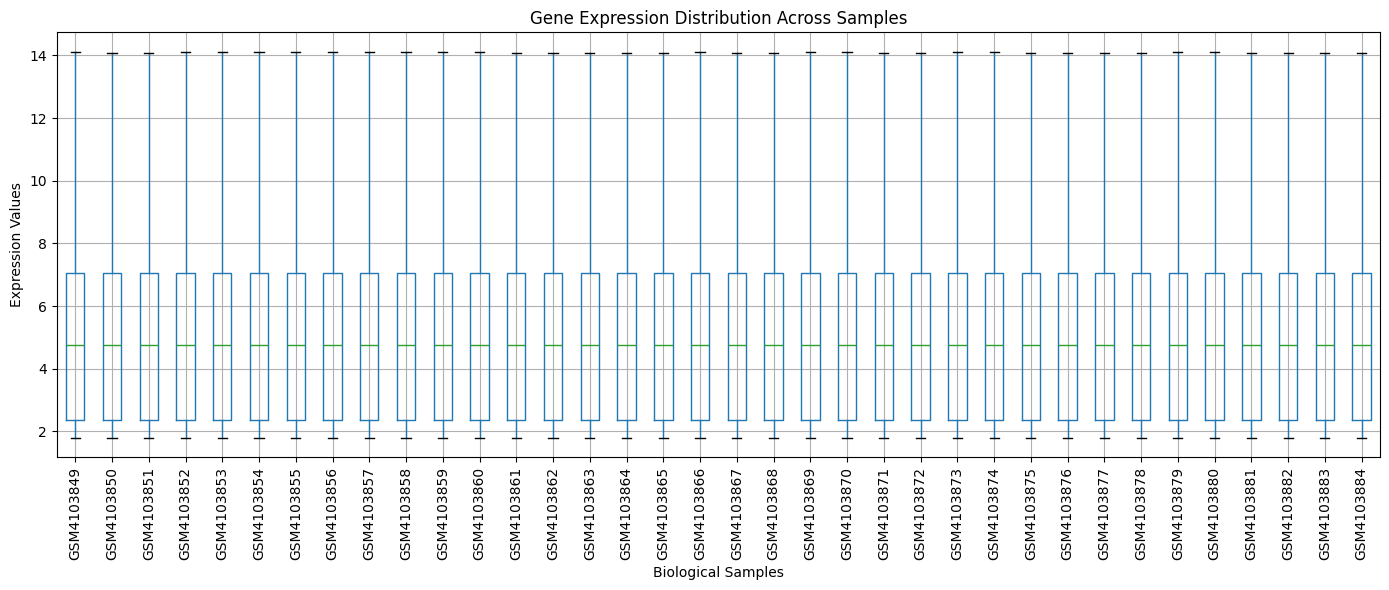

In [26]:
plt.figure(figsize=(14, 6))

data.iloc[:, 1:].boxplot(
    rot=90,
    showfliers=False
)

plt.title('Gene Expression Distribution Across Samples')
plt.xlabel('Biological Samples')
plt.ylabel('Expression Values')

plt.tight_layout()
plt.show()

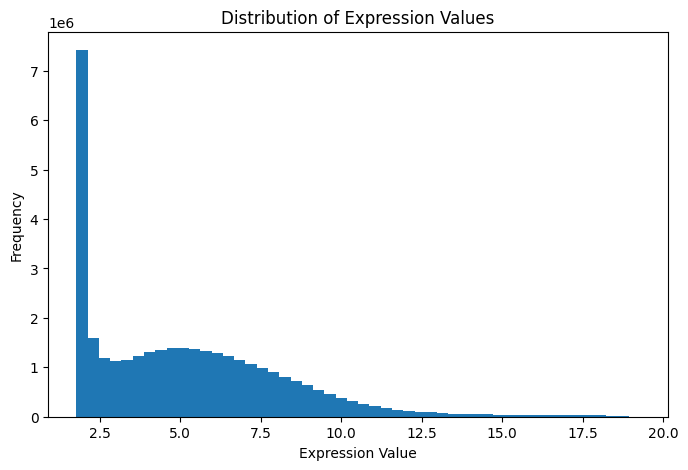

In [27]:
plt.figure(figsize=(8, 5))

plt.hist(
    data.iloc[:, 1:].values.flatten(),
    bins=50
)

plt.title('Distribution of Expression Values')
plt.xlabel('Expression Value')
plt.ylabel('Frequency')

plt.show()

In [28]:
sample_summary = data.iloc[:, 1:].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).T

sample_summary.index.name = 'GEO_ID'

sample_summary.head()

,count,mean,median,std,min,max
GEO_ID,,,,,,
GSM4103849,947672.0,5.190761,4.758399,3.051504,1.779997,19.277662
GSM4103850,947672.0,5.187876,4.754262,3.050854,1.779998,19.277662
GSM4103851,947672.0,5.190226,4.756824,3.051982,1.779997,19.277662
GSM4103852,947672.0,5.194504,4.762389,3.056405,1.779997,19.277662
GSM4103853,947672.0,5.189521,4.757724,3.053956,1.779998,19.277662


In [29]:
results = metadata.merge(
    sample_summary,
    on='GEO_ID'
)

results.head()

,GEO_ID,Sample_title,disease state,age,gender,tissue,count,mean,median,std,min,max
0,GSM4103849,Brain_AD_sample1,AD,76,w,brain,947672.0,5.190761,4.758399,3.051504,1.779997,19.277662
1,GSM4103850,Brain_AD_sample3,AD,79,m,brain,947672.0,5.187876,4.754262,3.050854,1.779998,19.277662
2,GSM4103851,Brain_AD_sample4,AD,98,w,brain,947672.0,5.190226,4.756824,3.051982,1.779997,19.277662
3,GSM4103852,Brain_AD_sample5,AD,73,w,brain,947672.0,5.194504,4.762389,3.056405,1.779997,19.277662
4,GSM4103853,Brain_AD_sample6,AD,81,w,brain,947672.0,5.189521,4.757724,3.053956,1.779998,19.277662


In [30]:
results.groupby('disease state')['mean'].agg(
    ['count', 'mean', 'std', 'min', 'max']
)

,count,mean,std,min,max
disease state,,,,,
AD,17,5.189554,0.002637,5.184578,5.194504
Control,19,5.187846,0.002542,5.181451,5.191779
